# CIFAR-10 Image Classification

32x32 color images of 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).
This is much harder than MNIST. I started with a simple CNN and then built a deeper one to fix the overfitting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Conv2D, MaxPool2D, Flatten, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix

## Loading the data

In [2]:
from tensorflow.keras.datasets import cifar10

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# labels come as shape (n, 1), make them flat
y_train = y_train.ravel()
y_test = y_test.ravel()

labels = ['airplane', 'automobile', 'bird', 'cat', 'deer',
          'dog', 'frog', 'horse', 'ship', 'truck']

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2456s 14us/step
(50000, 32, 32, 3) (50000,)
(10000, 32, 32, 3) (10000,)


## Looking at the data

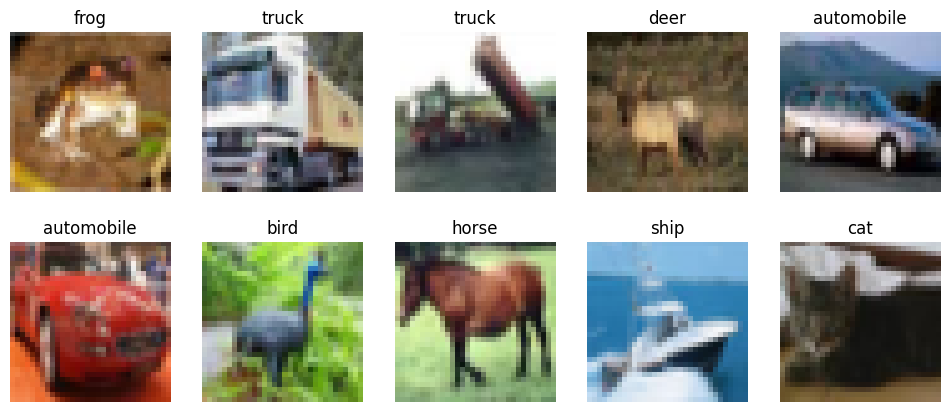

In [3]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(labels[y_train[i]])
    plt.axis('off')
plt.show()

## Preprocessing

The images are already `(32, 32, 3)` (3 color channels), so no reshape is needed. Only scaling and one-hot labels.

In [4]:
x_train = x_train / 255
x_test = x_test / 255

y_cat_train = to_categorical(y_train, 10)
y_cat_test = to_categorical(y_test, 10)

## Model 1 - simple CNN

In [5]:
model = Sequential()
model.add(Input(shape=(32, 32, 3)))

model.add(Conv2D(filters=32, kernel_size=(4, 4), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))

model.add(Conv2D(filters=32, kernel_size=(4, 4), activation='relu'))
model.add(MaxPool2D(pool_size=(2, 2)))

model.add(Flatten())
model.add(Dense(256, activation='relu'))
model.add(Dense(10, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='rmsprop', metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,610 (881.29 KB)

 Trainable params: 225,610 (881.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(x_train, y_cat_train,
                    epochs=15,
                    validation_split=0.1,
                    callbacks=[early_stop])

Epoch 1/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 17s 8ms/step - accuracy: 0.4436 - loss: 1.5575 - val_accuracy: 0.4976 - val_loss: 1.3890
Epoch 2/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5775 - loss: 1.2034 - val_accuracy: 0.5770 - val_loss: 1.2232
Epoch 3/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6351 - loss: 1.0471 - val_accuracy: 0.5150 - val_loss: 1.4441
Epoch 4/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6793 - loss: 0.9343 - val_accuracy: 0.6056 - val_loss: 1.2083
Epoch 5/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7087 - loss: 0.8414 - val_accuracy: 0.6548 - val_loss: 1.0236
Epoch 6/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7370 - loss: 0.7651 - val_accuracy: 0.6632 - val_loss: 1.0329
Epoch 7/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7620 - loss: 0.6964 - val_accuracy: 0.6632 - val_loss: 1.0927
Epoch 8/15
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7852 - loss: 0.6340 -

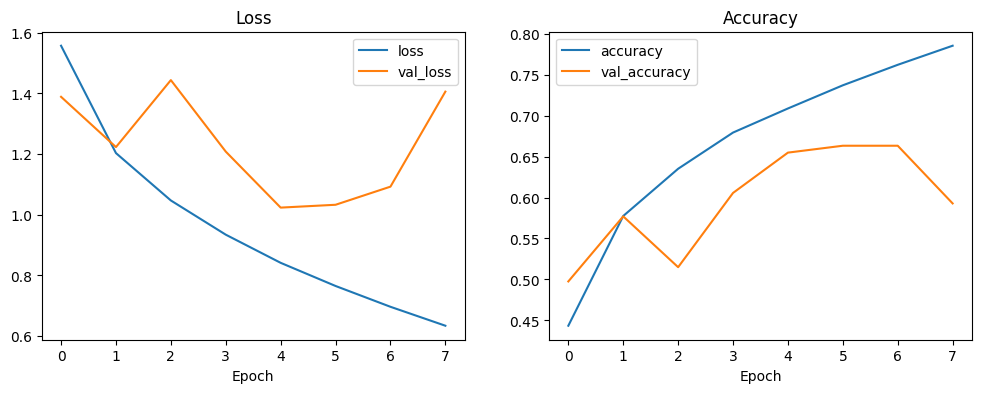

In [7]:
losses = pd.DataFrame(history.history)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
losses[['loss', 'val_loss']].plot(ax=ax[0], title='Loss')
losses[['accuracy', 'val_accuracy']].plot(ax=ax[1], title='Accuracy')
ax[0].set_xlabel('Epoch')
ax[1].set_xlabel('Epoch')
plt.show()

Training accuracy keeps going up but validation accuracy stops improving after a few epochs, so the model is overfitting.

## Model 2 - deeper CNN

Changes to fight the overfitting:
- two conv layers in each block and more filters (32 → 64)
- `BatchNormalization` after every conv layer
- `Dropout` after every block and before the output

In [8]:
model2 = Sequential()
model2.add(Input(shape=(32, 32, 3)))

model2.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
model2.add(BatchNormalization())
model2.add(Conv2D(32, (3, 3), padding='same', activation='relu'))
model2.add(BatchNormalization())
model2.add(MaxPool2D((2, 2)))
model2.add(Dropout(0.25))

model2.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
model2.add(BatchNormalization())
model2.add(Conv2D(64, (3, 3), padding='same', activation='relu'))
model2.add(BatchNormalization())
model2.add(MaxPool2D((2, 2)))
model2.add(Dropout(0.25))

model2.add(Flatten())
model2.add(Dense(256, activation='relu'))
model2.add(Dropout(0.5))
model2.add(Dense(10, activation='softmax'))

model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,117,738 (4.26 MB)

 Trainable params: 1,117,354 (4.26 MB)

 Non-trainable params: 384 (1.50 KB)

In [9]:
early_stop2 = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history2 = model2.fit(x_train, y_cat_train,
                      epochs=40,
                      batch_size=64,
                      validation_split=0.1,
                      callbacks=[early_stop2])

Epoch 1/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 32s 26ms/step - accuracy: 0.4013 - loss: 1.6857 - val_accuracy: 0.5036 - val_loss: 1.4598
Epoch 2/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.5453 - loss: 1.2824 - val_accuracy: 0.5876 - val_loss: 1.1329
Epoch 3/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6084 - loss: 1.1117 - val_accuracy: 0.6734 - val_loss: 0.9470
Epoch 4/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6512 - loss: 0.9990 - val_accuracy: 0.7078 - val_loss: 0.8355
Epoch 5/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.6833 - loss: 0.9097 - val_accuracy: 0.7446 - val_loss: 0.7436
Epoch 6/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7067 - loss: 0.8451 - val_accuracy: 0.7390 - val_loss: 0.7633
Epoch 7/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7278 - loss: 0.7820 - val_accuracy: 0.7524 - val_loss: 0.7354
Epoch 8/40
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7467 - loss: 0.7371 - val_accuracy: 

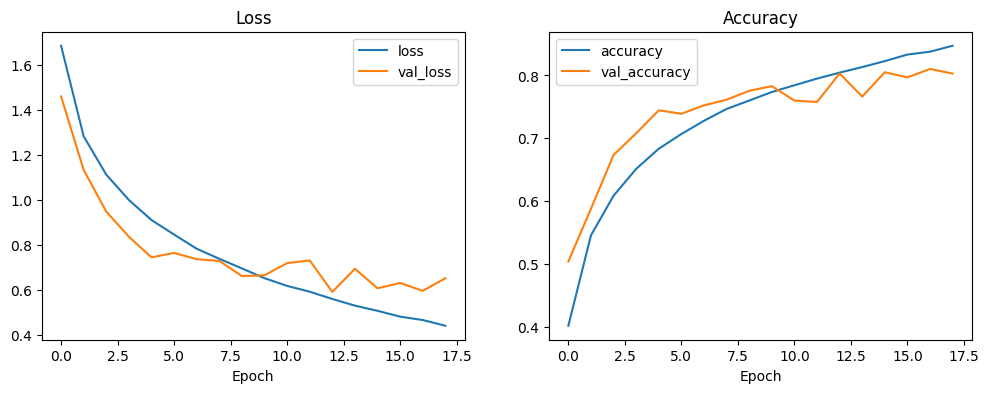

In [10]:
losses = pd.DataFrame(history2.history)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
losses[['loss', 'val_loss']].plot(ax=ax[0], title='Loss')
losses[['accuracy', 'val_accuracy']].plot(ax=ax[1], title='Accuracy')
ax[0].set_xlabel('Epoch')
ax[1].set_xlabel('Epoch')
plt.show()

## Comparing the two models on the test set

In [11]:
loss_1, acc_1 = model.evaluate(x_test, y_cat_test, verbose=0)
loss_2, acc_2 = model2.evaluate(x_test, y_cat_test, verbose=0)

print('Model 1 test accuracy:', round(acc_1, 4))
print('Model 2 test accuracy:', round(acc_2, 4))

Model 1 test accuracy: 0.6325
Model 2 test accuracy: 0.7934


In [12]:
predictions = model2.predict(x_test).argmax(axis=-1)

print(classification_report(y_test, predictions, target_names=labels))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
              precision    recall  f1-score   support

    airplane       0.78      0.83      0.80      1000
  automobile       0.89      0.93      0.91      1000
        bird       0.78      0.62      0.69      1000
         cat       0.59      0.64      0.62      1000
        deer       0.78      0.75      0.77      1000
         dog       0.72      0.69      0.70      1000
        frog       0.81      0.88      0.84      1000
       horse       0.81      0.86      0.83      1000
        ship       0.93      0.84      0.88      1000
       truck       0.86      0.90      0.88      1000

    accuracy                           0.79     10000
   macro avg       0.80      0.79      0.79     10000
weighted avg       0.80      0.79      0.79     10000



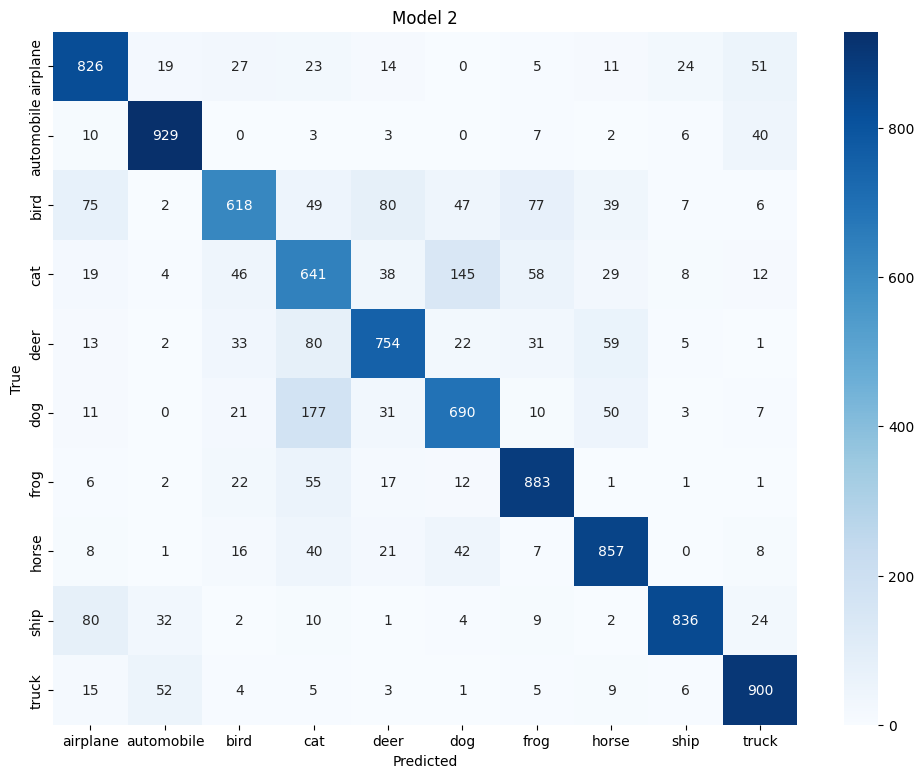

In [13]:
plt.figure(figsize=(12, 9))
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Model 2')
plt.show()

## Predicting a single image

In [14]:
def label_name(index):
    img = x_test[index]
    pred = model2.predict(img.reshape(1, 32, 32, 3), verbose=0).argmax(axis=-1)[0]
    plt.imshow(img)
    plt.title(f'Predicted: {labels[pred]}   True: {labels[y_test[index]]}')
    plt.axis('off')
    plt.show()

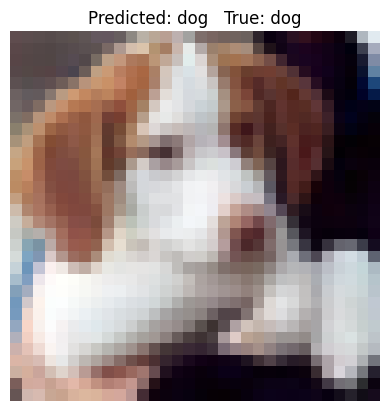

In [15]:
label_name(16)

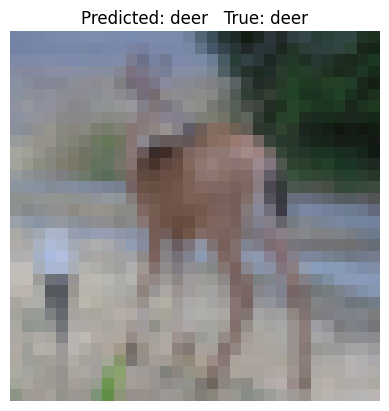

In [16]:
label_name(100)

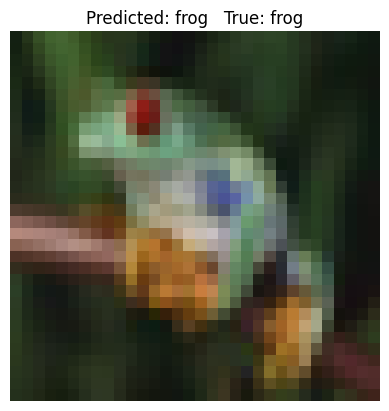

In [17]:
label_name(2024)